In [3]:
# Worlflow
# Insurance Cost data,/ Data analysis,/ Data preprocessing,/ Train Test split,/ Linear Regression,/ Trained Linear Regression Model
# New Data - Prediction

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn import metrics # for evaluation of model

In [13]:
# Data Collection and Processing
insurance_dataset = pd.read_csv('insurance.csv')
insurance_dataset.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [14]:
# number of rows and columns
insurance_dataset.shape

(1338, 7)

In [21]:
# Getting some information about the datasets
insurance_dataset.info()

# Checking for missing values
insurance_dataset.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB
               age          bmi     children       charges
count  1338.000000  1338.000000  1338.000000   1338.000000
mean     39.207025    30.663397     1.094918  13270.422265
std      14.049960     6.098187     1.205493  12110.011237
min      18.000000    15.960000     0.000000   1121.873900
25%      27.000000    26.296250     0.000000   4740.287150
50%      39.000000    30.400000     1.000000   9382.033000
75%      51.000000    34.693750     2.000000  16639.912515
max     

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [22]:
# 3 categorical features are :- Sex, Smoker, Region

# # duplicate values
# insurance_dataset.duplicated().sum()

# Data Analysis

In [25]:
# statistical measures of the datasets
insurance_dataset.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


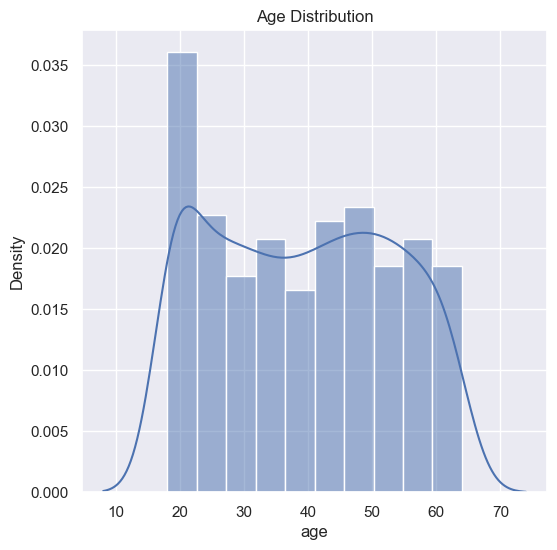

In [75]:
# we are going to find the distribution of the datasets
# 1st column age distribution
sns.set()
plt.figure(figsize=(6,6))
sns.histplot(data=insurance_dataset, x='age', stat='density', kde=True, bins=10, kde_kws={'cut':3})
plt.title("Age Distribution")
plt.show()

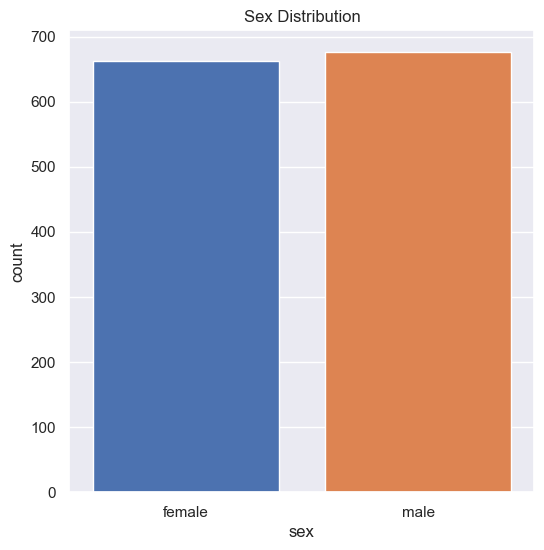

sex
male      676
female    662
Name: count, dtype: int64

In [71]:
# 2nd column sex distribution
# but we cannot use this graph for categorical columns so we are using the countoplot
plt.figure(figsize=(6,6))
sns.countplot(data=insurance_dataset, x='sex',hue='sex', saturation=1)
plt.title("Sex Distribution")
plt.show()

insurance_dataset['sex'].value_counts()

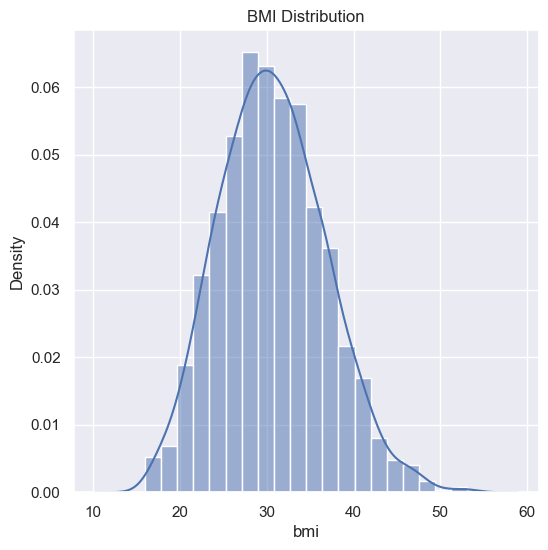

In [113]:
# 3rd column bmi distribution
sns.set()
plt.figure(figsize=(6,6))
sns.histplot(data=insurance_dataset, x='bmi', stat='density', bins=20, kde=True,  kde_kws={'cut':4})
plt.title("BMI Distribution")
plt.show()

# Normal BMI Range -> 18.5 to 24.9

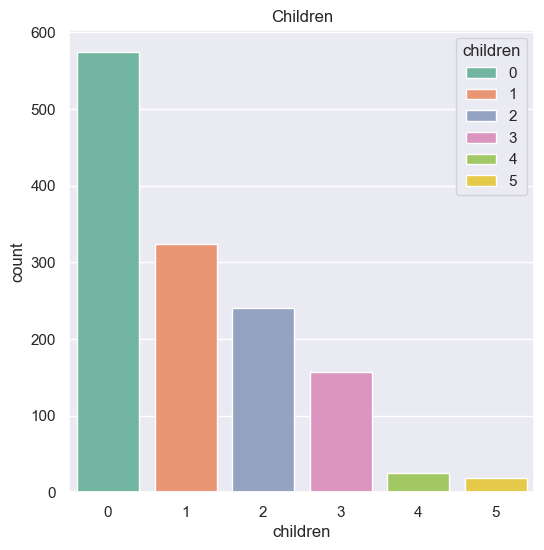

children
0    574
1    324
2    240
3    157
4     25
5     18
Name: count, dtype: int64

In [104]:
# 4th column is children
# it is numerical value but instead of using distribution plot we can use countplot 
# because this children column have only 5 or 6 value, so
plt.figure(figsize=(6,6))
sns.countplot(data=insurance_dataset, x='children', hue='children',
             palette='Set2')
plt.title("Children")
plt.show()

insurance_dataset['children'].value_counts()

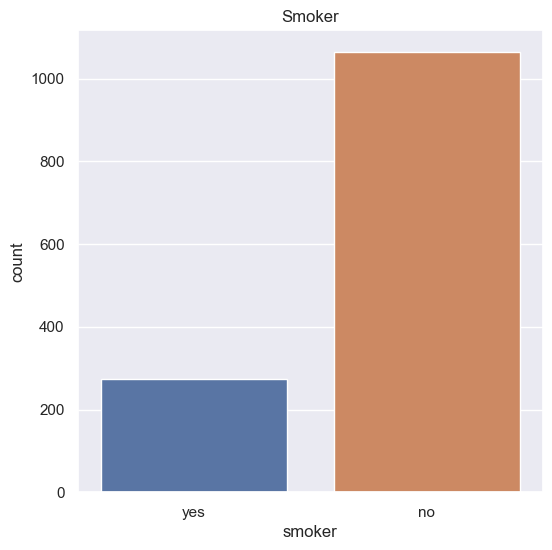

smoker
no     1064
yes     274
Name: count, dtype: int64

In [110]:
# 5th column smoker
plt.figure(figsize=(6,6))
sns.countplot(data=insurance_dataset, x='smoker',hue='smoker')
plt.title("Smoker")
plt.show()

insurance_dataset['smoker'].value_counts()

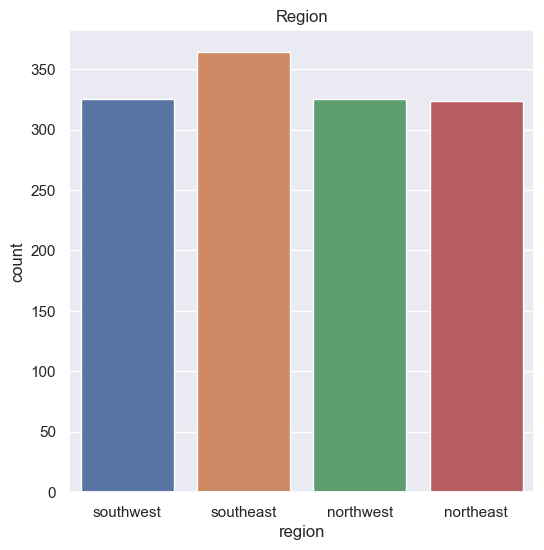

region
southeast    364
southwest    325
northwest    325
northeast    324
Name: count, dtype: int64

In [112]:
# 6th column region
plt.figure(figsize=(6,6))
sns.countplot(data=insurance_dataset, x='region', hue='region')
plt.title('Region')
plt.show()

insurance_dataset['region'].value_counts()

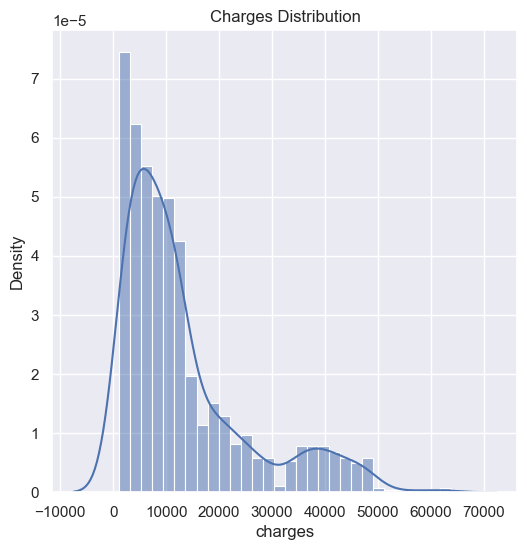

In [121]:
# 7th column Charges distribution
plt.figure(figsize=(6,6))
sns.histplot(data=insurance_dataset, x='charges', stat='density', kde=True, kde_kws={'cut':3})
plt.title("Charges Distribution")
plt.show()


# Data Pre-Processing

In [129]:
# we have categorical column- sex, smoker, region
# we can not feed this text data in model, because computer cannot understand text well so we need to encode this data

# 1. encoding 'sex' column
insurance_dataset.replace({
    "sex" : {'male':0, 'female':1} }, inplace = True)

# 2. encoding 'smoker' column 
insurance_dataset.replace({
    'smoker': {'yes':0, 'no':1} }, inplace=True)

# 3. encoding 'region' column
insurance_dataset.replace({
    'region': {'southeast':0, 'southwest':1, 'northeast':2, 'northwest':3}
}, inplace=True)


In [130]:
# Split the data into Features and Target
X = insurance_dataset.drop(columns='charges', axis=1)
Y = insurance_dataset['charges']


In [132]:
print(X)
print(Y)

      age  sex     bmi  children  smoker  region
0      19    1  27.900         0       0       1
1      18    0  33.770         1       1       0
2      28    0  33.000         3       1       0
3      33    0  22.705         0       1       3
4      32    0  28.880         0       1       3
...   ...  ...     ...       ...     ...     ...
1333   50    0  30.970         3       1       3
1334   18    1  31.920         0       1       2
1335   18    1  36.850         0       1       0
1336   21    1  25.800         0       1       1
1337   61    1  29.070         0       0       3

[1338 rows x 6 columns]
0       16884.92400
1        1725.55230
2        4449.46200
3       21984.47061
4        3866.85520
           ...     
1333    10600.54830
1334     2205.98080
1335     1629.83350
1336     2007.94500
1337    29141.36030
Name: charges, Length: 1338, dtype: float64


In [137]:
# Split dataset into Training and Testing
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=2)

print(X_train.shape)
print(X_test.shape)
print(Y_train.shape)
print(Y_test.shape)

(1070, 6)
(268, 6)
(1070,)
(268,)


# Model Training

In [138]:
# Linear Regression
# we have two axis X-features and Y-target y= mx+c

# Loading the Linear regression model
model = LinearRegression()
model.fit(X_train, Y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [142]:
# Model Evaluation
# 1. Prediction on training data
training_data_prediction = model.predict(X_train)
# this predict for X_train value, what are those Y-train values are and store in training_data_prediction variable

# the we need to find R square value for X_train and it values lies on 0-1
r2_train = metrics.r2_score(Y_train, training_data_prediction)
print("R2 Score for Training data", r2_train)
# as it is close to 1 the model is good -> 0.75

# 2. Prediction on testing data
testing_data_prediction = model.predict(X_test)
r2_test = metrics.r2_score(Y_test, testing_data_prediction)
print("R2 Score for Testing data", r2_test)
# -> 0.74

# training and testing accuracy both are approx same so this is Good fit model

R2 Score for Training data 0.751505643411174
R2 Score for Testing data 0.7447273869684077


# Building a Predictive System

In [156]:
# 55,female,32.775,2,no,northwest,12268.63225
input_data = (55,1,32.775,2,1,3)
# this is tuple, so we need to change it into numpy arrays
input_data_as_numpy_array = np.asarray(input_data)
# now we need to reshape this array
input_data_reshaped = input_data_as_numpy_array.reshape(1,-1)
# 1 rows and -1 means Numpy automatically calculates the number of columns based on the number of values

prediction = model.predict(input_data_reshaped)
print("The insurance cost in USD", prediction[0])

The insurance cost in USD 13917.116775271432


C:\Users\jiten\AppData\Roaming\Python\Python313\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
